# DJI Mini parts catalogue: model coverage and naming checks

**A buyer and repair-shop reference by Reboot Hub | Snapshot: 15 October 2026**

![174 dated Mini-series listings: Mini 3 32, Mini 3 Pro 34, Mini 4 Pro 36, Mini 5 Pro 72](https://reboot-hub.github.io/dji-drone-parts-reference/assets/mini-catalogue-20261015/mini-parts-cover.png)

## Goal

Use a real public catalogue to separate **model identity**, **assembly contents** and **disclosed condition** before selecting a replacement component. The four-model cohort contains **174 distinct listing URLs**. Two reproducible figures below show the model counts and naming details worth checking.

Reboot Hub is an independent specialist DJI parts retailer. For the current item details, use the [DJI Mini parts catalogue](https://reboot-hub.com/collections/dji-mini-series-spare-parts). This companion is retailer-published reference material; it does not establish universal compatibility, complete market coverage or manufacturer authorisation.

## Setup and source

This notebook uses the existing [dated public Kaggle release](https://www.kaggle.com/datasets/reboothub/dji-mini-parts-catalogue-october-2026), mirrored as an immutable JSON input at GitHub commit `c531e757ec7bccc7e87224ca73ca0def160e7e9c`. The code checks its SHA-256 before calculating results. No login, store credentials or live catalogue access is needed.

The cohort comprises listings created from 10 October 2026 onward that were active and publicly listed on 15 October. Creation time is not asserted to be first publication time. One row is one listing, rather than one engineering part number or unit in stock. No prices, transactions, acquisition costs or customer information are included.

Run with Python 3, `requests` and `matplotlib`; Colab normally includes these packages. The saved figures can also be read without running code. Product titles are supplier descriptions, not independently verified fitment records.

In [1]:
%matplotlib inline
from collections import Counter
from pathlib import Path
import hashlib, html, json, re
import requests
import matplotlib.pyplot as plt
from IPython.display import HTML, display

SOURCE_URL = 'https://raw.githubusercontent.com/Reboot-Hub/dji-drone-parts-reference/c531e757ec7bccc7e87224ca73ca0def160e7e9c/data/mini-parts-listings-20261015.json'
EXPECTED_SHA256 = 'bb856fd3d352d773e44678ab0ac9c92ad25f5ebb82190f6629e4c54b654dfc21'
response = requests.get(SOURCE_URL, timeout=30)
response.raise_for_status()
raw = response.content
assert hashlib.sha256(raw).hexdigest() == EXPECTED_SHA256, "Source fingerprint changed"
rows = json.loads(raw)
assert len(rows) == len({r['source_url'] for r in rows}) == 174
assert all(set(r) == {'aircraft_model','listing_title','source_url','snapshot_date'} for r in rows)
assert all(r['snapshot_date'] == '2026-10-15' for r in rows)
assert all(r['listing_title'].startswith('DJI '+r['aircraft_model']+' ') for r in rows)
assert all(r['source_url'].startswith('https://reboot-hub.com/products/') for r in rows)
models = ['Mini 3','Mini 3 Pro','Mini 4 Pro','Mini 5 Pro']
counts = Counter(r['aircraft_model'] for r in rows)
assert dict(counts) == {'Mini 3':32,'Mini 3 Pro':34,'Mini 4 Pro':36,'Mini 5 Pro':72}
FIGURE_DIR = Path('figures')
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.dpi':120,
                     'axes.spines.top':False,'axes.spines.right':False})
print("Verified:",len(rows),"unique public listing URLs; snapshot 2026-10-15")

Verified: 174 unique public listing URLs; snapshot 2026-10-15


## Step 1. Compare model coverage within this cohort

The bars count the selected listings for each model. They are not a measurement of how much of each aircraft is stocked or how complete the shop is relative to another supplier.

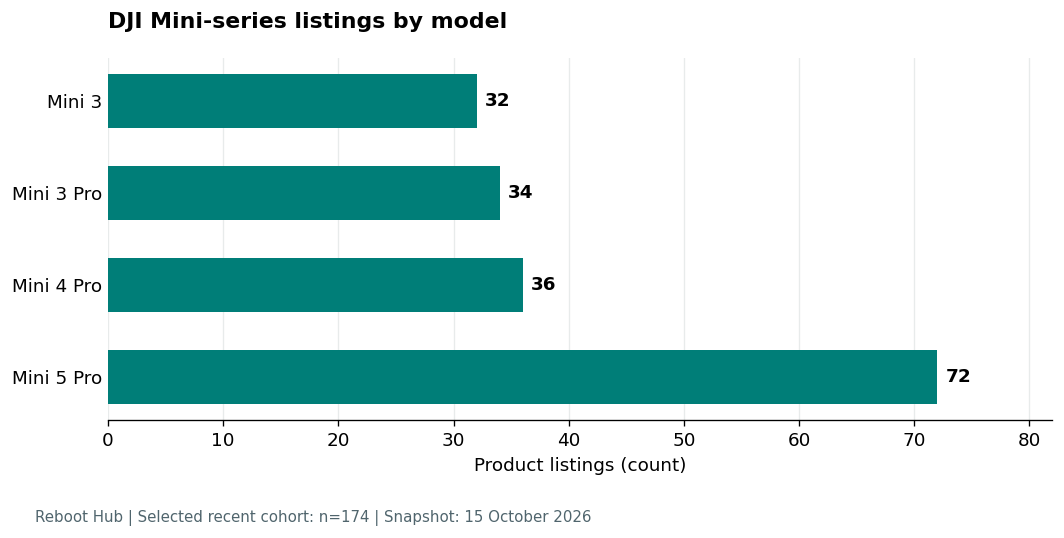

In [2]:
fig, ax = plt.subplots(figsize=(9,4.6))
bars = ax.barh(models,[counts[m] for m in models],color='#007E78',height=.58)
ax.invert_yaxis()
ax.set_xlim(0,82)
ax.set_xlabel('Product listings (count)')
ax.set_title('DJI Mini-series listings by model',loc='left',fontweight='bold',pad=18)
ax.bar_label(bars,padding=5,fontweight='bold')
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y',length=0)
ax.xaxis.grid(True,color='#D9DEDF',alpha=.6)
ax.set_axisbelow(True)
fig.text(.04,.02,'Reboot Hub | Selected recent cohort: n=174 | Snapshot: 15 October 2026',fontsize=9,color='#50656D')
fig.tight_layout(rect=(0,.07,1,.98))
fig.savefig(FIGURE_DIR/'model-listing-counts.png',dpi=160)
plt.show()

## Step 2. Find details that can change an order

Search the listing names for four explicit qualifiers. **A row can have more than one flag**, so the counts must not be added to estimate a number of distinct products. A zero means that the term was absent from the reviewed titles; it does not establish that the underlying hardware lacks that property.

These are text checks. “With” introduces contents in these titles; it does not by itself describe a complete repair kit. “Enhanced” requires item-specific clarification rather than an assumed performance benefit.

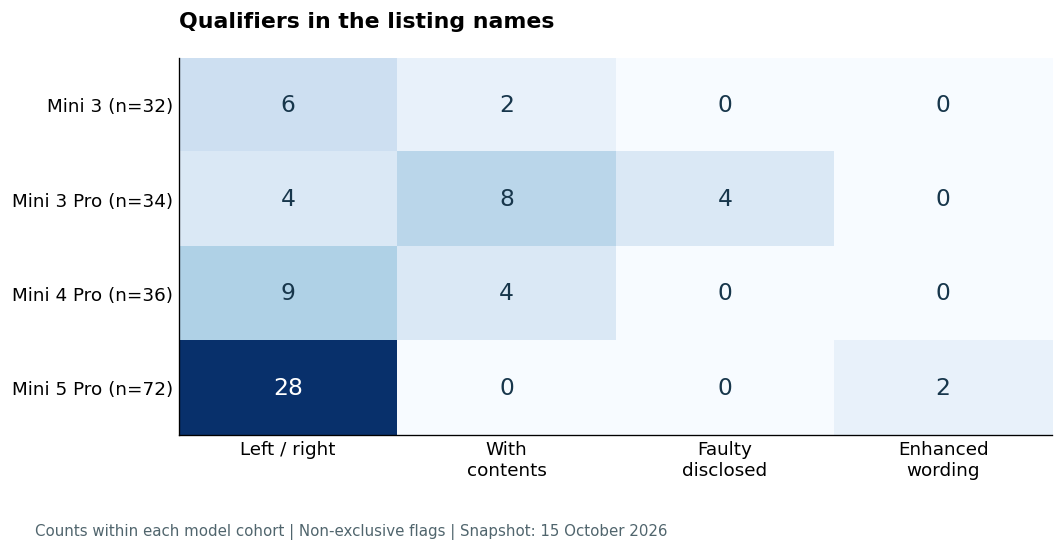

{'Left / right': 47, 'With contents': 14, 'Faulty disclosed': 4, 'Enhanced wording': 2}


In [3]:
patterns = {
    'Left / right': r'\b(left|right)\b',
    'With contents': r'\bwith\b',
    'Faulty disclosed': r'\bfaulty\b',
    'Enhanced wording': r'\benhanced\b',
}
flag_matrix = [[sum(bool(re.search(p,r['listing_title'],re.I))
                    for r in rows if r['aircraft_model']==model)
                for p in patterns.values()] for model in models]
totals = [sum(row[j] for row in flag_matrix) for j in range(len(patterns))]
assert totals == [47,14,4,2]
fig, ax = plt.subplots(figsize=(9,4.7))
ax.imshow(flag_matrix,cmap='Blues',vmin=0,vmax=max(max(r) for r in flag_matrix),aspect='auto')
ax.set_yticks(range(4),[f'{m} (n={counts[m]})' for m in models])
ax.set_xticks(range(4),['Left / right','With\ncontents','Faulty\ndisclosed','Enhanced\nwording'])
ax.set_title('Qualifiers in the listing names',loc='left',fontweight='bold',pad=18)
for i,row in enumerate(flag_matrix):
    for j,value in enumerate(row):
        ax.text(j,i,str(value),ha='center',va='center',fontsize=14,
                color='white' if value>max(max(r) for r in flag_matrix)/2 else '#17364B')
ax.tick_params(length=0)
fig.text(.04,.015,'Counts within each model cohort | Non-exclusive flags | Snapshot: 15 October 2026',fontsize=9,color='#50656D')
fig.tight_layout(rect=(0,.08,1,.98))
fig.savefig(FIGURE_DIR/'listing-name-qualifiers.png',dpi=160)
plt.show()
print(dict(zip(patterns,totals)))

## Step 3. Compare a real assembly pair

The Mini 3 Pro **GPS Module** and **GPS Module with Heat Sink Bracket** are separately named listings. The second title expressly includes a bracket. Compare the required assembly, pictured connectors and supplied contents before choosing; the titles do not establish that one substitutes for the other.

In [4]:
gps = [r for r in rows if r['aircraft_model']=='Mini 3 Pro' and 'GPS Module' in r['listing_title']]
assert len(gps)==2
table = '<table><tr><th>Listing</th><th>Check</th></tr>'
for r in gps:
    check = 'Bracket explicitly named; compare the complete pictured assembly.' if 'with Heat Sink Bracket' in r['listing_title'] else 'Bare-module listing; inspect pictured contents and connectors.'
    table += '<tr><td><a href="'+html.escape(r['source_url'],quote=True)+'">'+html.escape(r['listing_title'])+'</a></td><td>'+check+'</td></tr>'
display(HTML(table+'</table>'))

Listing,Check
DJI Mini 3 Pro GPS Module - OEM-pulled,Bare-module listing; inspect pictured contents and connectors.
DJI Mini 3 Pro GPS Module with Heat Sink Bracket - OEM-pulled,Bracket explicitly named; compare the complete pictured assembly.


## Checks and takeaways

- **174 unique URLs; four models.** The checksum and identity checks above protect the fixed snapshot from accidental replacement.
- **47** titles specify left/right position; **14** use “with”; **4** disclose a faulty component; **2** use “enhanced” wording. These groups overlap and are naming observations, not test results.
- A **rear arm shell with a faulty motor** does not describe a ready-to-use replacement motor. Read the disclosed condition before deciding whether it meets the repair scope.
- Exact-piece pictures help document visible condition and contents. They do not alone prove function, board revision, calibration status or cross-model fitment.

## Next steps

Use the [current DJI Mini parts catalogue](https://reboot-hub.com/collections/dji-mini-series-spare-parts) and [parts-selection guide](https://reboot-hub.com/pages/dji-parts-accessories-buying-guide) to inspect the exact item. If the failed component has not been identified, obtain a diagnosis before ordering. OEM-pulled components were previously installed and may have removal or handling marks.

This notebook is another access format for the dated retailer catalogue, not a second independent data source, inventory feed or market-completeness ranking. Reboot Hub is independent of DJI. Model names and trademarks identify the referenced equipment. This companion and its data retain Reboot Hub copyright; the earlier repository worksheet's CC BY licence is separate and unchanged.